### Dylan Renard
### Applied Machine Learning JHU
### Homework 13
### Professor Alhassan
### April 25th, 2026

## HW Assignment 13: Applied Machine Learning @JHU


#### Q1 Download  the dataset.  Unzip and  explore the file folders.  Load the image dataset with training  and testing  grouped.  (Note, cv2 reads  and saves in BGR channel order) Display a few images. How many color channels are there?

Base folder contents: ['seg_test', 'seg_train', 'seg_pred']
Training folders: ['forest', 'buildings', 'glacier', 'street', 'mountain', 'sea']
Testing folders: ['forest', 'buildings', 'glacier', 'street', 'mountain', 'sea']

Training image counts:
buildings: 2191
forest: 2271
glacier: 2404
mountain: 2512
sea: 2274
street: 2382

Testing image counts:
buildings: 437
forest: 474
glacier: 553
mountain: 525
sea: 510
street: 501

Total training images: 14034
Total testing images: 3000

Example image shape: (128, 128, 3)
Number of color channels: 3
Example loading runtime: 27.44 seconds


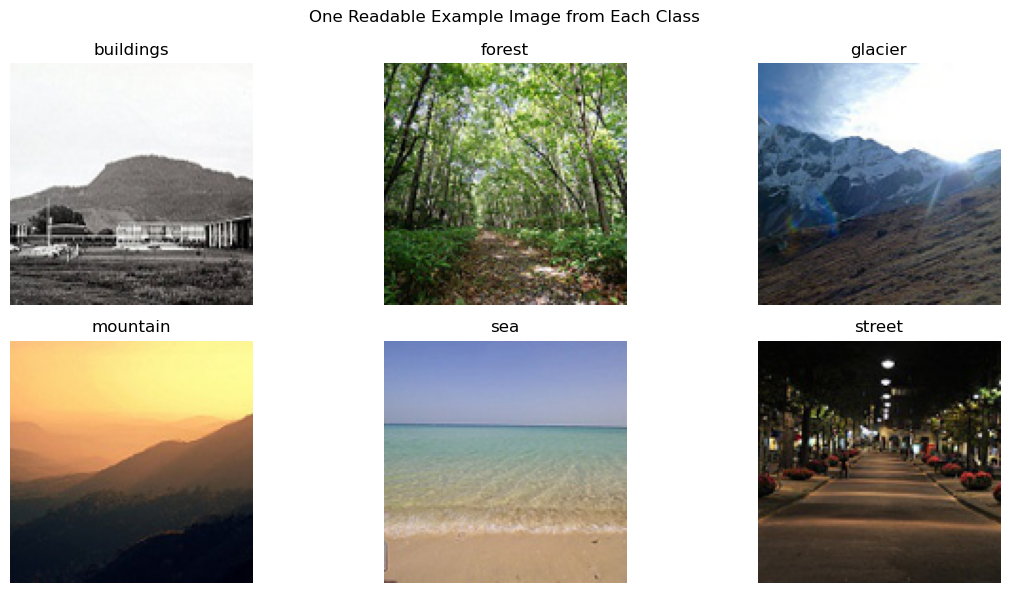

In [1]:

# Q1: Explore dataset folders, count files, and display one image per class

import os
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

IMGSIZE = (128, 128)

BASE_PATH = "IntelImageData"
CNAMES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

train_dir = os.path.join(BASE_PATH, "seg_train", "seg_train")
test_dir  = os.path.join(BASE_PATH, "seg_test", "seg_test")

print("Base folder contents:", os.listdir(BASE_PATH))
print("Training folders:", os.listdir(train_dir))
print("Testing folders:", os.listdir(test_dir))

def count_images_by_class(split_dir):
    counts = {}
    for label in CNAMES:
        path = os.path.join(split_dir, label)
        files = [f for f in os.listdir(path) if f.lower().endswith(".jpg")]
        counts[label] = len(files)
    return counts

train_counts = count_images_by_class(train_dir)
test_counts = count_images_by_class(test_dir)

print("\nTraining image counts:")
for label, count in train_counts.items():
    print(f"{label}: {count}")

print("\nTesting image counts:")
for label, count in test_counts.items():
    print(f"{label}: {count}")

print("\nTotal training images:", sum(train_counts.values()))
print("Total testing images:", sum(test_counts.values()))

def find_first_readable_image(class_dir):
    files = sorted([f for f in os.listdir(class_dir) if f.lower().endswith(".jpg")])

    for f in files:
        img_path = os.path.join(class_dir, f)
        try:
            with Image.open(img_path) as img:
                img = img.convert("RGB")
                img = img.resize(IMGSIZE)
                arr = np.asarray(img, dtype=np.uint8)
            return arr, img_path
        except Exception:
            continue

    raise ValueError(f"No readable images found in {class_dir}")

example_images = []
example_paths = []

start = time.time()

for label in CNAMES:
    class_dir = os.path.join(train_dir, label)
    img_arr, img_path = find_first_readable_image(class_dir)
    example_images.append(img_arr)
    example_paths.append(img_path)

print("\nExample image shape:", example_images[0].shape)
print("Number of color channels:", example_images[0].shape[2])
print("Example loading runtime:", round(time.time() - start, 2), "seconds")

plt.figure(figsize=(12, 6))

for i, label in enumerate(CNAMES):
    plt.subplot(2, 3, i + 1)
    plt.imshow(example_images[i])
    plt.title(label)
    plt.axis("off")

plt.suptitle("One Readable Example Image from Each Class")
plt.tight_layout()
plt.show()

#### Q2 Covert the imageset to numpy array, such as the array size: (14034, 128, 128, 3) Scale the imageset to [0-1].

In [4]:
# Q2 cache reload check

import os
import numpy as np

q2_cache_files = [
    "X_tr_q2_subset_scaled.npy",
    "X_ts_q2_subset_scaled.npy",
    "y_tr_q2_subset.npy",
    "y_ts_q2_subset.npy"
]

if all(os.path.exists(f) for f in q2_cache_files):
    print("Q2 cache found. Loading arrays from cache...")

    X_tr = np.load("X_tr_q2_subset_scaled.npy")
    X_ts = np.load("X_ts_q2_subset_scaled.npy")
    y_tr = np.load("y_tr_q2_subset.npy")
    y_ts = np.load("y_ts_q2_subset.npy")

    print("Loaded Q2 cache.")
    print("X_tr shape:", X_tr.shape)
    print("X_ts shape:", X_ts.shape)
    print("y_tr shape:", y_tr.shape)
    print("y_ts shape:", y_ts.shape)
    print("X_tr dtype:", X_tr.dtype)
    print("X_ts dtype:", X_ts.dtype)
    print("Pixel range:", X_tr.min(), "to", X_tr.max())

else:
    print("Q2 cache not found. Run the image-loading/scaling code, then save cache.")

Q2 cache found. Loading arrays from cache...
Loaded Q2 cache.
X_tr shape: (450, 128, 128, 3)
X_ts shape: (150, 128, 128, 3)
y_tr shape: (450,)
y_ts shape: (150,)
X_tr dtype: float32
X_ts dtype: float32
Pixel range: 0.0 to 1.0


In [2]:
# Q2: Parallel image loading into NumPy arrays and scaling to [0, 1]

import os
import time
import numpy as np
import matplotlib.image as mpimg
from skimage.transform import resize
from concurrent.futures import ThreadPoolExecutor

IMGSIZE = (128, 128)

BASE_PATH = "IntelImageData"
CNAMES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

train_dir = os.path.join(BASE_PATH, "seg_train", "seg_train")
test_dir  = os.path.join(BASE_PATH, "seg_test", "seg_test")

N_TRAIN_PER_CLASS = 75
N_TEST_PER_CLASS = 25
MAX_SCAN_PER_CLASS = 250
MAX_WORKERS = 8

def build_items(split_dir, n_per_class, max_scan_per_class):
    items = []

    for label in CNAMES:
        path = os.path.join(split_dir, label)
        files = sorted([f for f in os.listdir(path) if f.lower().endswith(".jpg")])
        files_to_scan = files[:max_scan_per_class]
        label_id = CNAMES.index(label)

        # Add candidates; actual cap is enforced after successful reads
        for f in files_to_scan:
            img_path = os.path.join(path, f)
            items.append((img_path, label_id, n_per_class))

        print(
            f"{label}: {len(files)} files found; scanning up to {len(files_to_scan)}",
            flush=True
        )

    return items

def load_one_image_matplotlib(item):
    img_path, label_id, _ = item

    try:
        img = mpimg.imread(img_path)

        # Handle grayscale images if encountered
        if img.ndim == 2:
            img = np.stack([img, img, img], axis=-1)

        # Drop alpha channel if encountered
        if img.shape[-1] == 4:
            img = img[:, :, :3]

        # Resize to 128 x 128
        img = resize(
            img,
            IMGSIZE,
            anti_aliasing=True,
            preserve_range=True
        )

        img = np.asarray(img, dtype=np.float32)

        return img, label_id, img_path, None

    except Exception as e:
        return None, label_id, img_path, str(e)

def load_subset_parallel(split_dir, n_per_class, max_scan_per_class, max_workers=8):
    items = build_items(split_dir, n_per_class, max_scan_per_class)

    X_list = []
    y_list = []
    failed = []
    class_counts = {i: 0 for i in range(len(CNAMES))}

    start = time.time()

    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        for i, (img, label_id, img_path, error_msg) in enumerate(
            executor.map(load_one_image_matplotlib, items)
        ):
            if img is None:
                failed.append((img_path, error_msg))
            else:
                # Keep only up to n_per_class successful images per class
                if class_counts[label_id] < n_per_class:
                    X_list.append(img)
                    y_list.append(label_id)
                    class_counts[label_id] += 1

            if (i + 1) % 500 == 0:
                print(
                    f"processed {i + 1}/{len(items)} files | "
                    f"loaded {len(X_list)} | failed {len(failed)} | "
                    f"{time.time() - start:.1f}s",
                    flush=True
                )

            # Stop early if all classes have enough images
            if all(count >= n_per_class for count in class_counts.values()):
                print("Reached target images for all classes.", flush=True)
                break

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.int64)

    print("\nClass counts loaded:")
    for i, class_name in enumerate(CNAMES):
        print(f"{class_name}: {np.sum(y == i)}")

    print("Failed reads:", len(failed))

    return X, y, failed

start = time.time()

print("Loading training subset...")
X_tr, y_tr, failed_train = load_subset_parallel(
    train_dir,
    N_TRAIN_PER_CLASS,
    MAX_SCAN_PER_CLASS,
    MAX_WORKERS
)

print("\nLoading testing subset...")
X_ts, y_ts, failed_test = load_subset_parallel(
    test_dir,
    N_TEST_PER_CLASS,
    MAX_SCAN_PER_CLASS,
    MAX_WORKERS
)

# Scale to [0, 1]
if X_tr.max() > 1.0:
    X_tr = X_tr / 255.0

if X_ts.max() > 1.0:
    X_ts = X_ts / 255.0

print("\nQ2 Results")
print("X_tr shape:", X_tr.shape)
print("X_ts shape:", X_ts.shape)
print("y_tr shape:", y_tr.shape)
print("y_ts shape:", y_ts.shape)
print("X_tr dtype:", X_tr.dtype)
print("X_ts dtype:", X_ts.dtype)
print("Pixel range:", X_tr.min(), "to", X_tr.max())
print("Failed training reads:", len(failed_train))
print("Failed testing reads:", len(failed_test))
print("Runtime:", round(time.time() - start, 2), "seconds")

assert X_tr.ndim == 4 and X_tr.shape[1:] == (128, 128, 3)
assert X_ts.ndim == 4 and X_ts.shape[1:] == (128, 128, 3)
assert y_tr.shape[0] == X_tr.shape[0]
assert y_ts.shape[0] == X_ts.shape[0]

Loading training subset...
buildings: 2191 files found; scanning up to 250
forest: 2271 files found; scanning up to 250
glacier: 2404 files found; scanning up to 250
mountain: 2512 files found; scanning up to 250
sea: 2274 files found; scanning up to 250
street: 2382 files found; scanning up to 250
processed 500/1500 files | loaded 150 | failed 246 | 129.1s
processed 1000/1500 files | loaded 300 | failed 539 | 264.8s
Reached target images for all classes.

Class counts loaded:
buildings: 75
forest: 75
glacier: 75
mountain: 75
sea: 75
street: 75
Failed reads: 819

Loading testing subset...
buildings: 437 files found; scanning up to 250
forest: 474 files found; scanning up to 250
glacier: 553 files found; scanning up to 250
mountain: 525 files found; scanning up to 250
sea: 510 files found; scanning up to 250
street: 501 files found; scanning up to 250
processed 500/1500 files | loaded 50 | failed 268 | 125.6s
processed 1000/1500 files | loaded 100 | failed 629 | 310.7s
Reached target im

In [3]:
# Cache the successfully loaded and scaled Q2 arrays

np.save("X_tr_q2_subset_scaled.npy", X_tr)
np.save("X_ts_q2_subset_scaled.npy", X_ts)
np.save("y_tr_q2_subset.npy", y_tr)
np.save("y_ts_q2_subset.npy", y_ts)

print("Q2 cache saved successfully.")
print("X_tr:", X_tr.shape)
print("X_ts:", X_ts.shape)
print("y_tr:", y_tr.shape)
print("y_ts:", y_ts.shape)
print("Pixel range:", X_tr.min(), "to", X_tr.max())

Q2 cache saved successfully.
X_tr: (450, 128, 128, 3)
X_ts: (150, 128, 128, 3)
y_tr: (450,)
y_ts: (150,)
Pixel range: 0.0 to 1.0


#### Q3: Create a neural network to train and report its performance on the testing portion of the dataset. 60% reclassification and 55% testing performance should be achievable without any hyperparameter tuning. (Hint: My model with 3 hidden layers of 50 nodes per layer, which is similar to the model in the module notebook, took around 5 mins to train 200 epochs.)

##### Reminder, you have to convert the 3D image (includign the color channel) to a linear vector in case you use fully connected layers at the input, x = torch.flatten(_X, start_dim=1)

##### (Hint, for debugging use print statements or PyCharm to display the tensor shapes)


In [5]:
# Q3: Fully connected PyTorch neural network for image classification

import torch
import torch.nn as nn
import torch.optim as optim
import time

np.random.seed(0)
torch.manual_seed(0)

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_tr, dtype=torch.float32)
y_train_tensor = torch.tensor(y_tr, dtype=torch.long)

X_test_tensor = torch.tensor(X_ts, dtype=torch.float32)
y_test_tensor = torch.tensor(y_ts, dtype=torch.long)

print("Original training tensor shape:", X_train_tensor.shape)
print("Original testing tensor shape:", X_test_tensor.shape)

# Flatten images from (N, 128, 128, 3) to (N, 49152)
X_train_tensor = torch.flatten(X_train_tensor, start_dim=1)
X_test_tensor = torch.flatten(X_test_tensor, start_dim=1)

print("Flattened training tensor shape:", X_train_tensor.shape)
print("Flattened testing tensor shape:", X_test_tensor.shape)

# Move tensors to device
X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)
X_test_tensor = X_test_tensor.to(device)
y_test_tensor = y_test_tensor.to(device)

print("Input min/max:", X_train_tensor.min().item(), X_train_tensor.max().item())
print("Training label counts:", torch.unique(y_train_tensor.cpu(), return_counts=True))
print("Testing label counts:", torch.unique(y_test_tensor.cpu(), return_counts=True))

# Define fully connected neural network
class ImageMLP(nn.Module):
    def __init__(self, input_dim, output_dim=6):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, output_dim)
        
    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = self.fc4(x)
        return x

input_dim = X_train_tensor.shape[1]
model = ImageMLP(input_dim=input_dim, output_dim=len(CNAMES)).to(device)

print(model)

loss_func = nn.CrossEntropyLoss()

# Adam tends to behave better than high-learning-rate SGD on this flattened image setup
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 75
minibatch_size = 512

start_time = time.time()

for epoch in range(epochs):
    model.train()
    indices = torch.randperm(X_train_tensor.shape[0], device=device)
    epoch_loss = 0.0
    
    for start_idx in range(0, X_train_tensor.shape[0], minibatch_size):
        batch_idx = indices[start_idx:start_idx + minibatch_size]
        
        X_batch = X_train_tensor[batch_idx]
        y_batch = y_train_tensor[batch_idx]
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = loss_func(outputs, y_batch)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
    
    if (epoch + 1) % 5 == 0 or epoch == 0:
        model.eval()
        with torch.no_grad():
            train_outputs = model(X_train_tensor)
            train_pred = torch.argmax(train_outputs, dim=1)
            train_acc = (train_pred == y_train_tensor).float().mean().item()
            
            test_outputs = model(X_test_tensor)
            test_pred = torch.argmax(test_outputs, dim=1)
            test_acc = (test_pred == y_test_tensor).float().mean().item()
        
        print(
            f"Epoch {epoch + 1:3d}/{epochs} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Test Acc: {test_acc:.4f}"
        )

end_time = time.time()
print(f"\nTraining time: {(end_time - start_time) / 60:.2f} minutes")

Using device: mps
Original training tensor shape: torch.Size([450, 128, 128, 3])
Original testing tensor shape: torch.Size([150, 128, 128, 3])
Flattened training tensor shape: torch.Size([450, 49152])
Flattened testing tensor shape: torch.Size([150, 49152])
Input min/max: 0.0 1.0
Training label counts: (tensor([0, 1, 2, 3, 4, 5]), tensor([75, 75, 75, 75, 75, 75]))
Testing label counts: (tensor([0, 1, 2, 3, 4, 5]), tensor([25, 25, 25, 25, 25, 25]))
ImageMLP(
  (fc1): Linear(in_features=49152, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=64, bias=True)
  (fc4): Linear(in_features=64, out_features=6, bias=True)
)
Epoch   1/75 | Loss: 1.7961 | Train Acc: 0.1667 | Test Acc: 0.1667
Epoch   5/75 | Loss: 1.8718 | Train Acc: 0.2044 | Test Acc: 0.2200
Epoch  10/75 | Loss: 1.7009 | Train Acc: 0.2978 | Test Acc: 0.2533
Epoch  15/75 | Loss: 1.5856 | Train Acc: 0.4111 | Test Acc: 0.3733
Epoch  20/75 | Loss: 1

In [6]:
model.eval()

with torch.no_grad():
    train_outputs = model(X_train_tensor)
    train_pred = torch.argmax(train_outputs, dim=1)
    train_acc = (train_pred == y_train_tensor).float().mean().item()
    
    test_outputs = model(X_test_tensor)
    test_pred = torch.argmax(test_outputs, dim=1)
    test_acc = (test_pred == y_test_tensor).float().mean().item()

print(f"Final training/reclassification accuracy: {train_acc * 100:.2f}%")
print(f"Final testing accuracy: {test_acc * 100:.2f}%")

Final training/reclassification accuracy: 78.44%
Final testing accuracy: 45.33%


##### Q4: Research and find out how to improve the neural network model to solve this problem. Outline an approach

A fully connected neural network is a reasonable baseline, but it is not ideal for image classification. After resizing to 128 x 128 pixels, each RGB image still contains 49,152 input values. Flattening the image removes spatial relationships among neighboring pixels, which are important for detecting edges, textures, shapes, and larger visual patterns. It also makes the first dense layer very large, increasing memory use and the risk of overfitting.

A better approach would be to use a convolutional neural network (CNN). Convolutional layers preserve spatial structure and learn local filters that can detect visual features across the image. Pooling layers can reduce spatial dimensions while keeping important features, and dropout or batch normalization can improve generalization.

Transfer learning would likely improve performance even more. Instead of training a model from scratch, I could use a pretrained CNN such as ResNet, VGG, EfficientNet, or MobileNet as a feature extractor. These models have already learned useful visual patterns from large image datasets. The earlier convolutional layers could be frozen, and the final classification layer could be replaced with a new six-class output layer for the Intel image categories. This would reduce training time, improve generalization, and make better use of a smaller dataset.

The model could also be improved with data augmentation, such as random horizontal flips, rotations, crops, brightness changes, and contrast changes. This would expose the model to more image variation and reduce overfitting.

Another practical improvement would be to make preprocessing more robust and efficient. In this notebook, image decoding was the main bottleneck, so caching the processed NumPy arrays helped avoid repeated JPG decoding. With more time, a more robust parallel preprocessing pipeline could be built using multiprocessing or a PyTorch DataLoader with multiple workers. GPU acceleration could also be useful for pixel-level preprocessing steps after decoding, such as resizing, normalization, and batch tensor construction.

In [8]:
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import models
import time

# Use MPS first on M1 Mac
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

# Convert image arrays from NHWC -> NCHW for CNNs
# Current X_tr shape: (N, 128, 128, 3)
X_train_cnn = torch.tensor(X_tr, dtype=torch.float32).permute(0, 3, 1, 2)
X_test_cnn = torch.tensor(X_ts, dtype=torch.float32).permute(0, 3, 1, 2)

y_train_cnn = torch.tensor(y_tr, dtype=torch.long)
y_test_cnn = torch.tensor(y_ts, dtype=torch.long)

print("CNN training tensor shape:", X_train_cnn.shape)
print("CNN testing tensor shape:", X_test_cnn.shape)

batch_size = 32

train_loader_cnn = DataLoader(
    TensorDataset(X_train_cnn, y_train_cnn),
    batch_size=batch_size,
    shuffle=True
)

test_loader_cnn = DataLoader(
    TensorDataset(X_test_cnn, y_test_cnn),
    batch_size=batch_size,
    shuffle=False
)

# Load pretrained MobileNetV2
mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Freeze pretrained feature extractor layers
for param in mobilenet.features.parameters():
    param.requires_grad = False

# Replace classifier for 6 Intel image classes
mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    len(CNAMES)
)

model_cnn = mobilenet.to(device)

print(model_cnn.classifier)

loss_func = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_cnn.classifier.parameters(), lr=0.001)

def evaluate_cnn(model, data_loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)
            preds = torch.argmax(outputs, dim=1)

            correct += (preds == y_batch).sum().item()
            total += y_batch.size(0)

    return correct / total

epochs = 10
start_time = time.time()

for epoch in range(epochs):
    model_cnn.train()
    epoch_loss = 0.0

    for X_batch, y_batch in train_loader_cnn:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        outputs = model_cnn(X_batch)
        loss = loss_func(outputs, y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    train_acc = evaluate_cnn(model_cnn, train_loader_cnn)
    test_acc = evaluate_cnn(model_cnn, test_loader_cnn)

    print(
        f"Epoch {epoch + 1:2d}/{epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f}"
    )

print(f"\nTransfer learning demo runtime: {(time.time() - start_time) / 60:.2f} minutes")

final_train_acc_cnn = evaluate_cnn(model_cnn, train_loader_cnn)
final_test_acc_cnn = evaluate_cnn(model_cnn, test_loader_cnn)

print(f"Final pretrained CNN training accuracy: {final_train_acc_cnn * 100:.2f}%")
print(f"Final pretrained CNN testing accuracy: {final_test_acc_cnn * 100:.2f}%")

Using device: mps
CNN training tensor shape: torch.Size([450, 3, 128, 128])
CNN testing tensor shape: torch.Size([150, 3, 128, 128])


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /Users/drenard921/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100.0%


Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=6, bias=True)
)
Epoch  1/10 | Loss: 23.3084 | Train Acc: 0.8044 | Test Acc: 0.7333
Epoch  2/10 | Loss: 15.9473 | Train Acc: 0.8867 | Test Acc: 0.7733
Epoch  3/10 | Loss: 12.8304 | Train Acc: 0.9111 | Test Acc: 0.8267
Epoch  4/10 | Loss: 9.6111 | Train Acc: 0.9156 | Test Acc: 0.7800
Epoch  5/10 | Loss: 9.0078 | Train Acc: 0.9333 | Test Acc: 0.8133
Epoch  6/10 | Loss: 7.4877 | Train Acc: 0.9422 | Test Acc: 0.8200
Epoch  7/10 | Loss: 7.2235 | Train Acc: 0.9422 | Test Acc: 0.8400
Epoch  8/10 | Loss: 6.9377 | Train Acc: 0.9467 | Test Acc: 0.8000
Epoch  9/10 | Loss: 6.6526 | Train Acc: 0.9489 | Test Acc: 0.8333
Epoch 10/10 | Loss: 6.4916 | Train Acc: 0.9578 | Test Acc: 0.8200

Transfer learning demo runtime: 0.37 minutes
Final pretrained CNN training accuracy: 95.78%
Final pretrained CNN testing accuracy: 82.00%


#### Reference

Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.